Live deployment: https://heart-disease-prediction-mlf.streamlit.app/
GitHub repository: https://github.com/Waqar-Farrukh/heart-disease-prediction

# Heart Disease Prediction System

Name: Waqar Farrukh  
Roll number: FA24-BSE-118  
Section: BSE-A  
Course: Machine Learning Fundamentals AIC354

Predict heart disease presence using exactly four input attributes.

## Input and output

| Input | Meaning |
|---|---|
| age | Age in years |
| cp | Chest pain type: 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina: 0 no, 1 yes |

Output: 0 disease absent, 1 disease present. The original num values 1–4 are grouped as disease present.

## Step 1 Import libraries

In [1]:
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from IPython.display import display

## Step 2 Load sample data

In [2]:
columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
heart_data = pd.read_csv('processed_cleveland.csv', header=None,
                         names=columns, na_values='?')
display(heart_data.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Source: [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease). Use the processed Cleveland file. It has no header row.

## Step 3 Understand and preprocess sample data

### Step 3.1 Understand sample data

In [3]:
print('Rows and columns:', heart_data.shape)
print('Columns:', heart_data.columns.tolist())
heart_data.info()
display(heart_data.isna().sum().to_frame('Missing values'))

Rows and columns: (303, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,Missing values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


### Step 3.2 Preprocess sample data

Missing markers are converted to NaN. The selected four inputs and target have no missing values. Rows are removed only if a selected input or target is missing.

In [4]:
features = ['age', 'cp', 'thalach', 'exang']
rows_before = len(heart_data)
heart_data = heart_data.dropna(subset=features + ['num']).copy()
heart_data['HeartDisease'] = np.where(heart_data['num'] > 0, 'Yes', 'No')
print('Rows removed:', rows_before - len(heart_data))
print('Rows retained:', len(heart_data))
display(heart_data['HeartDisease'].value_counts().to_frame('Count'))

Rows removed: 0
Rows retained: 303


,Count
HeartDisease,
No,164
Yes,139


## Step 4 Feature extraction

Age describes the patient. Chest pain type and exercise-induced angina describe symptoms. Maximum heart rate describes exercise response. These four attributes are fixed before evaluating the test set.

In [5]:
sample_data = heart_data[features + ['HeartDisease']].copy()
sample_data.to_csv('heart-disease-four-features.csv', index=False)
display(sample_data.head())
print('Input attributes:', len(features))

,age,cp,thalach,exang,HeartDisease
0,63.0,1.0,150.0,0.0,No
1,67.0,4.0,108.0,1.0,Yes
2,67.0,4.0,129.0,1.0,Yes
3,37.0,3.0,187.0,0.0,No
4,41.0,2.0,172.0,0.0,No


Input attributes: 4


## Step 5 Label encoding

### Step 5.1 Train the label encoders

In [6]:
target_encoder = LabelEncoder().fit(['No', 'Yes'])
print(dict(zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))))

{np.str_('No'): np.int64(0), np.str_('Yes'): np.int64(1)}


### Step 5.2 Label encode the output

In [7]:
sample_data_encoded_output = sample_data.copy()
sample_data_encoded_output['HeartDisease'] = target_encoder.transform(sample_data['HeartDisease'])
display(sample_data_encoded_output.head())

,age,cp,thalach,exang,HeartDisease
0,63.0,1.0,150.0,0.0,0
1,67.0,4.0,108.0,1.0,1
2,67.0,4.0,129.0,1.0,1
3,37.0,3.0,187.0,0.0,0
4,41.0,2.0,172.0,0.0,0


### Step 5.3 Encode the inputs

The inputs are already numerical. Keep age and heart rate as measurements, and retain the existing cp and exang category codes. Scaling is fitted on training data inside the model pipeline.

In [8]:
sample_data_encoded = sample_data_encoded_output.copy()
sample_data_encoded[features] = sample_data_encoded[features].astype(float)
sample_data_encoded.to_csv('sample-data-encoded.csv', index=False)
display(sample_data_encoded.head())

,age,cp,thalach,exang,HeartDisease
0,63.0,1.0,150.0,0.0,0
1,67.0,4.0,108.0,1.0,1
2,67.0,4.0,129.0,1.0,1
3,37.0,3.0,187.0,0.0,0
4,41.0,2.0,172.0,0.0,0


## Step 6 Execute the training phase

### Step 6.1 Split training and testing data

In [9]:
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded, test_size=0.2, random_state=0, stratify=sample_data_encoded['HeartDisease']
)
training_data_encoded = training_data_encoded.copy()
testing_data_encoded = testing_data_encoded.copy()
training_data_encoded.to_csv('training-data-encoded.csv', index=False)
testing_data_encoded.to_csv('testing-data-encoded.csv', index=False)
print('Training shape:', training_data_encoded.shape)
print('Testing shape:', testing_data_encoded.shape)

Training shape: (242, 5)
Testing shape: (61, 5)


### Step 6.2 Separate training inputs and labels

In [10]:
input_vector_train = training_data_encoded[features]
output_label_train = training_data_encoded['HeartDisease']
print('Input shape:', input_vector_train.shape)
print('Output shape:', output_label_train.shape)

Input shape: (242, 4)
Output shape: (242,)


### Step 6.3 Train the Support Vector Classifier

In [11]:
svc_model = make_pipeline(StandardScaler(), SVC(gamma='auto', random_state=0))
svc_model.fit(input_vector_train, output_label_train)
print(svc_model)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svc', SVC(gamma='auto', random_state=0))])


### Step 6.4 Save the trained model

In [12]:
with open('heart_disease_model.pkl', 'wb') as file:
    pickle.dump(svc_model, file)
print('Saved: heart_disease_model.pkl')

Saved: heart_disease_model.pkl


## Step 7 Execute the testing phase

### Step 7.1 Separate testing inputs and labels

In [13]:
input_vector_test = testing_data_encoded[features]
output_label_test = testing_data_encoded['HeartDisease']
print('Input shape:', input_vector_test.shape)
print('Output shape:', output_label_test.shape)

Input shape: (61, 4)
Output shape: (61,)


### Step 7.2 Load the saved model

In [14]:
with open('heart_disease_model.pkl', 'rb') as file:
    model = pickle.load(file)
print('Saved model loaded')

Saved model loaded


### Step 7.3 Predict on testing data

In [15]:
predictions = model.predict(input_vector_test)
model_predictions = testing_data_encoded.copy()
model_predictions['Predictions'] = predictions
model_predictions.to_csv('model-predictions.csv', index=False)
display(model_predictions)

,age,cp,thalach,exang,HeartDisease,Predictions
125,45.0,2.0,175.0,0.0,0,0
83,68.0,3.0,150.0,1.0,1,1
53,44.0,2.0,188.0,0.0,0,0
45,58.0,3.0,165.0,0.0,1,0
248,52.0,4.0,168.0,0.0,1,0
...,...,...,...,...,...,...
132,29.0,2.0,202.0,0.0,0,0
15,57.0,3.0,174.0,0.0,0,0
96,59.0,4.0,142.0,1.0,1,1
208,55.0,2.0,155.0,0.0,0,0


### Step 7.4 Calculate accuracy

In [16]:
accuracy = accuracy_score(output_label_test, predictions)
print(f'Accuracy: {accuracy:.4f} ({accuracy:.2%})')

Accuracy: 0.7869 (78.69%)


### Step 7.5 Precision recall F1 and confusion matrix

                 precision    recall  f1-score   support

 Disease absent       0.74      0.94      0.83        33
Disease present       0.89      0.61      0.72        28

       accuracy                           0.79        61
      macro avg       0.82      0.77      0.78        61
   weighted avg       0.81      0.79      0.78        61



,Disease absent,Disease present
Disease absent,31,2
Disease present,11,17


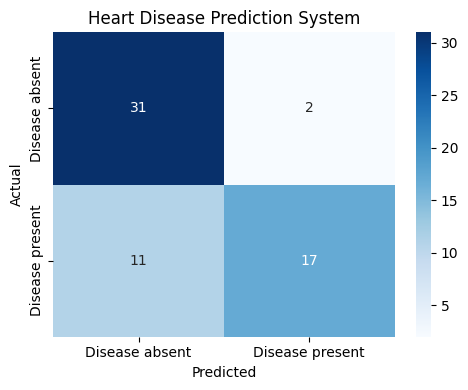

In [17]:
class_names = ['Disease absent', 'Disease present']
print(classification_report(output_label_test, predictions, labels=[0, 1],
                            target_names=class_names, zero_division=0))
conf_matrix = confusion_matrix(output_label_test, predictions, labels=[0, 1])
display(pd.DataFrame(conf_matrix, index=class_names, columns=class_names))
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Heart Disease Prediction System')
plt.tight_layout()
plt.savefig('confusion-matrix.png', dpi=150)
plt.show()
results = {
    'accuracy': float(accuracy),
    'training_rows': len(training_data_encoded),
    'testing_rows': len(testing_data_encoded),
    'features': features,
    'confusion_matrix': conf_matrix.tolist(),
    'classification_report': classification_report(
        output_label_test, predictions, labels=[0, 1],
        target_names=class_names, output_dict=True, zero_division=0
    )
}
with open('results.json', 'w') as file:
    json.dump(results, file, indent=2)

## Step 8 Execute the application phase

### Step 8.1 Take user input

In [18]:
age_input = 63.0
cp_input = 1.0
thalach_input = 150.0
exang_input = 0.0
print(age_input, cp_input, thalach_input, exang_input)

63.0 1.0 150.0 0.0


Change these example values to test another input. The deployed form accepts user selections.

### Step 8.2 Create the input feature vector

In [19]:
user_input = pd.DataFrame({'age': [age_input], 'cp': [cp_input], 'thalach': [thalach_input], 'exang': [exang_input]})
display(user_input)

,age,cp,thalach,exang
0,63.0,1.0,150.0,0.0


### Step 8.3 Apply the same input representation

In [20]:
unseen_data_features = user_input[features].astype(float)
display(unseen_data_features)

,age,cp,thalach,exang
0,63.0,1.0,150.0,0.0


### Step 8.4 Load the saved model

In [21]:
with open('heart_disease_model.pkl', 'rb') as file:
    model = pickle.load(file)

### Step 8.5 Return the prediction

In [22]:
prediction = int(model.predict(unseen_data_features)[0])
print(class_names[prediction])

Disease absent


## Step 9 Execute the feedback phase

### Step 9.1 Review feedback

The following feedback comes from the actual test results. External user and domain expert feedback has not yet been collected.

In [23]:
feedback = pd.DataFrame({
    'Reviewer': ['Test result review', 'Test result review'],
    'Observation': ['Positive cases missed', 'Negative cases predicted positive'],
    'Count': [int(conf_matrix[1, 0]), int(conf_matrix[0, 1])]
})
feedback.to_csv('feedback-review.csv', index=False)
display(feedback)

,Reviewer,Observation,Count
0,Test result review,Positive cases missed,11
1,Test result review,Negative cases predicted positive,2


### Step 9.2 Identify improvements

In [24]:
improvements = ['Review missed positive cases',
                'Evaluate class balancing using training folds',
                'Collect real user and domain expert feedback']
for improvement in improvements:
    print(improvement)

Review missed positive cases
Evaluate class balancing using training folds
Collect real user and domain expert feedback


### Step 9.3 Evaluate a possible improvement

In [25]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
candidate_model = make_pipeline(StandardScaler(), SVC(gamma='auto', random_state=0, class_weight='balanced'))
baseline_scores = cross_val_score(svc_model, input_vector_train, output_label_train,
                                  cv=folds, scoring='balanced_accuracy')
candidate_scores = cross_val_score(candidate_model, input_vector_train, output_label_train,
                                   cv=folds, scoring='balanced_accuracy')
display(pd.DataFrame({
    'Model': ['Original SVC', 'Class-balanced SVC'],
    'Mean training CV balanced accuracy': [baseline_scores.mean(), candidate_scores.mean()]
}))
print('The saved model remains the original SVC. The candidate needs further review.')

,Model,Mean training CV balanced accuracy
0,Original SVC,0.730777
1,Class-balanced SVC,0.735115


The saved model remains the original SVC. The candidate needs further review.


## Step 10 Deploy the trained model

The deployed Streamlit app is linked in the first cell of this notebook. The app in app.py loads heart_disease_model.pkl and uses the same four inputs, category codes, fitted scaler and SVC model as this notebook. The project repository is also linked in the first cell. See README.md for instructions to run the app locally. The JSON export below is an optional copy of model parameters.

In [26]:
if hasattr(model, 'named_steps'):
    classifier = model.named_steps['svc']
    scaler = model.named_steps['standardscaler']
    mean = scaler.mean_.tolist()
    scale = scaler.scale_.tolist()
else:
    classifier = model
    mean = [0.0] * len(features)
    scale = [1.0] * len(features)
model_parameters = {
    'features': features,
    'classes': classifier.classes_.tolist(),
    'support_vectors': classifier.support_vectors_.tolist(),
    'dual_coefficients': classifier.dual_coef_[0].tolist(),
    'intercept': float(classifier.intercept_[0]),
    'gamma': float(classifier._gamma),
    'mean': mean,
    'scale': scale,
    'class_names': class_names,
    'accuracy': float(accuracy)
}

In [27]:
with open('model_parameters.json', 'w') as file:
    json.dump(model_parameters, file, indent=2)
print('Cloud model parameters exported')

Cloud model parameters exported


## Conclusion

In [28]:
print(f'Test accuracy: {accuracy:.2%}')
print('Training, testing, application, and test-result review completed.')
print('External user feedback has not been collected; record genuine feedback if required by the instructor.')

Test accuracy: 78.69%
Training, testing, application, and test-result review completed.
External user feedback has not been collected; record genuine feedback if required by the instructor.


Adapted from the [provided Titanic teaching notebooks](https://github.com/haqnawaz99/ml-teaching-notebooks), originally developed by Mohsin Afzal and Dr. Rao Muhammad Adeel Nawab.

Dataset: Janosi, Steinbrunn, Pfisterer and Detrano. Heart Disease. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X. CC BY 4.0.